<a href="https://colab.research.google.com/github/umetaisa2004-commits/content-ops-starter/blob/main/20261005_PhotronImport.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!unzip -q /content/20261005Photron.zip -d /content/images

全 105 枚の画像を処理中...
----------------------------------------
解析完了！Excelを出力しました: /content/Floc_Analysis_Result.xlsx
----------------------------------------


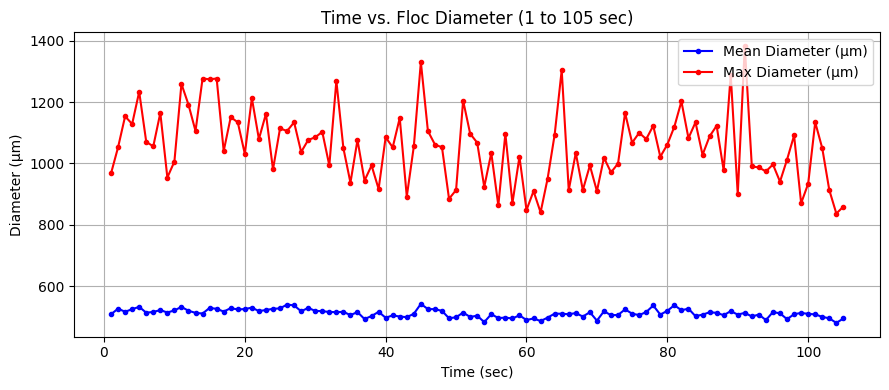

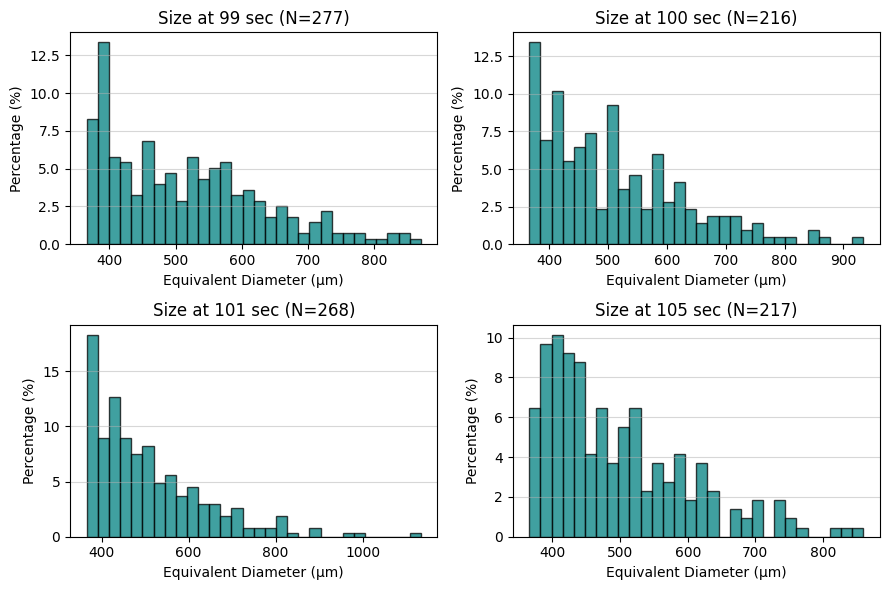

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
import pandas as pd

# --- 1. 処理設定 ---
folder_path = "/content/images" # 解凍先のフォルダパス

# 105枚目までを対象にする
image_paths = sorted(glob.glob(os.path.join(folder_path, "*.bmp")))[:105]

# 1ピクセルあたりのμm（前回のご指摘に合わせて100にしています。適宜変更してください）
scale_factor = 28.98

# 指定された出力秒数
target_seconds = [99, 100, 101, 105]

time_list = []
mean_diameters = []
max_diameters = []
dist_data = {sec: [] for sec in target_seconds}

print(f"全 {len(image_paths)} 枚の画像を処理中...")

# --- 2. 画像の連続読み込みと解析 ---
for idx, path in enumerate(image_paths):
    sec = idx + 1

    img_gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img_gray is None:
        continue

    blurred = cv2.GaussianBlur(img_gray, (3, 3), 0)
    flocs_mask = cv2.adaptiveThreshold(blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 31, 5)
    kernel = np.ones((3, 3), np.uint8)
    flocs_mask = cv2.morphologyEx(flocs_mask, cv2.MORPH_OPEN, kernel, iterations=1)

    contours, _ = cv2.findContours(flocs_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    diameters_um = []

    for cnt in contours:
        area = cv2.contourArea(cnt)
        if area > 10:
            diameter_px = 2 * np.sqrt(area / np.pi)
            # 【重要】ピクセルからμmへの変換を掛け算に修正
            diameter_um = diameter_px * scale_factor
            diameters_um.append(diameter_um)

    # 時間ごとの集計
    time_list.append(sec)
    if len(diameters_um) > 0:
        mean_diameters.append(np.mean(diameters_um))
        max_diameters.append(np.max(diameters_um))
    else:
        mean_diameters.append(np.nan)
        max_diameters.append(np.nan)

    # 特定の秒数の分布データを保持
    if sec in target_seconds:
        dist_data[sec] = diameters_um

# --- 3. Excelファイルへの出力 ---
excel_filename = "/content/Floc_Analysis_Result.xlsx"
with pd.ExcelWriter(excel_filename) as writer:
    # シート1: 時間変化
    df_time = pd.DataFrame({"時間 (秒)": time_list, "平均径 (µm)": mean_diameters, "最大径 (µm)": max_diameters})
    df_time.to_excel(writer, sheet_name="時間変化", index=False)

    # シート2: 粒度分布（99, 100, 101, 105秒）
    df_list = []
    for sec in target_seconds:
        data = dist_data[sec]
        if len(data) > 0:
            # グラフと同じくデータを30分割して、それぞれの数と割合を計算
            counts, bin_edges = np.histogram(data, bins=30)
            bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2 # 階級値（ビンの中央値）
            percentages = counts / len(data) * 100

            df_sec = pd.DataFrame({
                f"{sec}秒_粒径(µm)": np.round(bin_centers, 1),
                f"{sec}秒_数": counts,
                f"{sec}秒_割合(%)": np.round(percentages, 2)
            })
        else:
            df_sec = pd.DataFrame({f"{sec}秒_粒径(µm)": [], f"{sec}秒_数": [], f"{sec}秒_割合(%)": []})

        df_list.append(df_sec)

    # 4つの秒数のDataFrameを横に連結（4セットの列ができる）
    df_dist_final = pd.concat(df_list, axis=1)
    df_dist_final.to_excel(writer, sheet_name="粒度分布_最終盤", index=False)

print("-" * 40)
print(f"解析完了！Excelを出力しました: {excel_filename}")
print("-" * 40)

# --- 4. グラフの描画 ---
# スクロールしなくても見やすくなるように figsize を縮小
plt.figure(figsize=(9, 4))
plt.plot(time_list, mean_diameters, marker='.', label="Mean Diameter (µm)", color='blue', linestyle='-')
plt.plot(time_list, max_diameters, marker='.', label="Max Diameter (µm)", color='red', linestyle='-')
plt.title("Time vs. Floc Diameter (1 to 105 sec)")
plt.xlabel("Time (sec)")
plt.ylabel("Diameter (µm)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(9, 6))
axes = axes.flatten()

for i, sec in enumerate(target_seconds):
    data = dist_data[sec]
    if len(data) > 0:
        weights = np.ones(len(data)) / len(data) * 100
        axes[i].hist(data, bins=30, weights=weights, color='teal', alpha=0.75, edgecolor='black')
        axes[i].set_title(f"Size at {sec} sec (N={len(data)})")
        axes[i].set_xlabel("Equivalent Diameter (µm)")
        axes[i].set_ylabel("Percentage (%)")
        axes[i].grid(axis='y', alpha=0.5)
    else:
        axes[i].set_title(f"Size at {sec} sec (No flocs found)")
        axes[i].axis('off')

plt.tight_layout()
plt.show()

全 105 枚の画像を処理中...


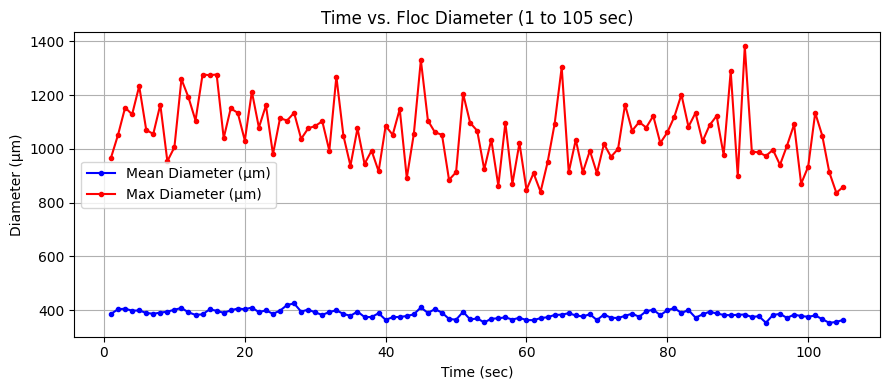

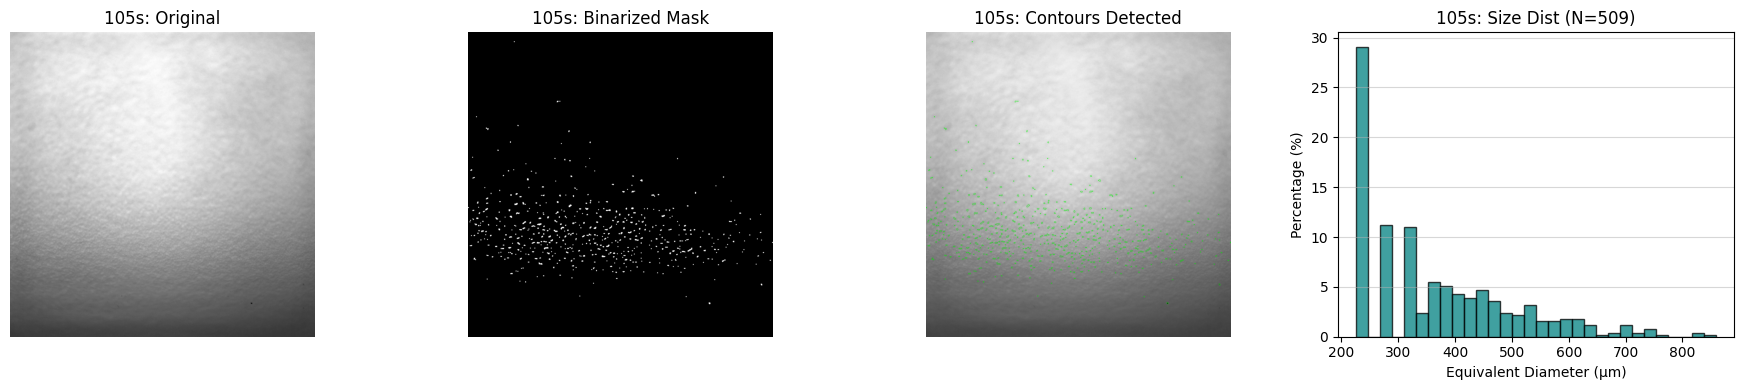

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
import pandas as pd

# --- 1. 処理設定 ---
folder_path = "/content/images"
image_paths = sorted(glob.glob(os.path.join(folder_path, "*.bmp")))[:105]

scale_factor = 100  # 1px = 100µm

time_list = []
mean_diameters = []
max_diameters = []
dist_data_105 = []

# 105枚目の可視化用データ保持
img_105_orig = None
mask_105 = None
contours_105 = None

print(f"全 {len(image_paths)} 枚の画像を処理中...")

# --- 2. 画像の連続読み込みと解析 ---
for idx, path in enumerate(image_paths):
    sec = idx + 1

    img_gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img_gray is None:
        continue

    blurred = cv2.GaussianBlur(img_gray, (3, 3), 0)
    flocs_mask = cv2.adaptiveThreshold(blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 31, 5)
    kernel = np.ones((3, 3), np.uint8)
    flocs_mask = cv2.morphologyEx(flocs_mask, cv2.MORPH_OPEN, kernel, iterations=1)

    contours, _ = cv2.findContours(flocs_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    diameters_um = []

    # 105枚目の画像・マスク・輪郭を保存
    if sec == 105:
        img_105_orig = img_gray.copy()
        mask_105 = flocs_mask.copy()
        contours_105_list = []

    for cnt in contours:
        area = cv2.contourArea(cnt)
        # より小さな粒子を拾うため閾値を2ピクセルに引き下げ
        if area >= 2:
            diameter_px = 2 * np.sqrt(area / np.pi)
            diameter_um = diameter_px * scale_factor
            diameters_um.append(diameter_um)

            if sec == 105:
                contours_105_list.append(cnt)

    time_list.append(sec)
    if len(diameters_um) > 0:
        mean_diameters.append(np.mean(diameters_um))
        max_diameters.append(np.max(diameters_um))
    else:
        mean_diameters.append(np.nan)
        max_diameters.append(np.nan)

    if sec == 105:
        dist_data_105 = diameters_um
        contours_105 = contours_105_list

# --- 3. Excelファイルへの出力 ---
excel_filename = "/content/Floc_Analysis_Result.xlsx"
with pd.ExcelWriter(excel_filename) as writer:
    # シート1: 時間変化
    df_time = pd.DataFrame({"時間 (秒)": time_list, "平均径 (µm)": mean_diameters, "最大径 (µm)": max_diameters})
    df_time.to_excel(writer, sheet_name="時間変化", index=False)

    # シート2: 粒度分布（105秒のみ）
    if len(dist_data_105) > 0:
        counts, bin_edges = np.histogram(dist_data_105, bins=30)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        percentages = counts / len(dist_data_105) * 100
        df_dist = pd.DataFrame({
            "105秒_粒径(µm)": np.round(bin_centers, 1),
            "105秒_数": counts,
            "105秒_割合(%)": np.round(percentages, 2)
        })
    else:
        df_dist = pd.DataFrame({"105秒_粒径(µm)": [], "105秒_数": [], "105秒_割合(%)": []})

    df_dist.to_excel(writer, sheet_name="粒度分布_105秒", index=False)

# --- 4. グラフと画像描画 ---
# ① 時間変化の折れ線グラフ
plt.figure(figsize=(9, 4))
plt.plot(time_list, mean_diameters, marker='.', label="Mean Diameter (µm)", color='blue', linestyle='-')
plt.plot(time_list, max_diameters, marker='.', label="Max Diameter (µm)", color='red', linestyle='-')
plt.title("Time vs. Floc Diameter (1 to 105 sec)")
plt.xlabel("Time (sec)")
plt.ylabel("Diameter (µm)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ② 105枚目の詳細解析ビュー (1x4の横並び)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

# 元画像
axes[0].imshow(img_105_orig, cmap='gray')
axes[0].set_title("105s: Original")
axes[0].axis('off')

# 二値化画像
axes[1].imshow(mask_105, cmap='gray')
axes[1].set_title("105s: Binarized Mask")
axes[1].axis('off')

# 輪郭描画画像 (見やすくするため白黒画像をBGRに変換して緑色で縁取り)
img_contours = cv2.cvtColor(img_105_orig, cv2.COLOR_GRAY2BGR)
cv2.drawContours(img_contours, contours_105, -1, (0, 255, 0), 1)
axes[2].imshow(cv2.cvtColor(img_contours, cv2.COLOR_BGR2RGB))
axes[2].set_title("105s: Contours Detected")
axes[2].axis('off')

# 粒度分布ヒストグラム
if len(dist_data_105) > 0:
    weights = np.ones(len(dist_data_105)) / len(dist_data_105) * 100
    axes[3].hist(dist_data_105, bins=30, weights=weights, color='teal', alpha=0.75, edgecolor='black')
    axes[3].set_title(f"105s: Size Dist (N={len(dist_data_105)})")
    axes[3].set_xlabel("Equivalent Diameter (µm)")
    axes[3].set_ylabel("Percentage (%)")
    axes[3].grid(axis='y', alpha=0.5)
else:
    axes[3].set_title("105s: No flocs found")
    axes[3].axis('off')

plt.tight_layout()
plt.show()

全 105 枚の画像を処理中...


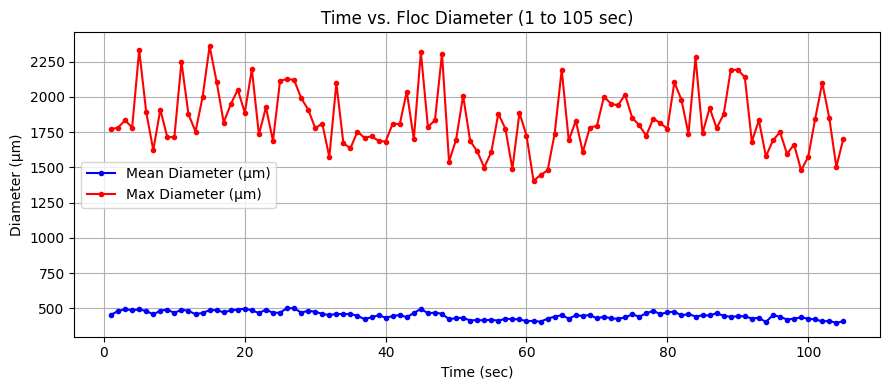

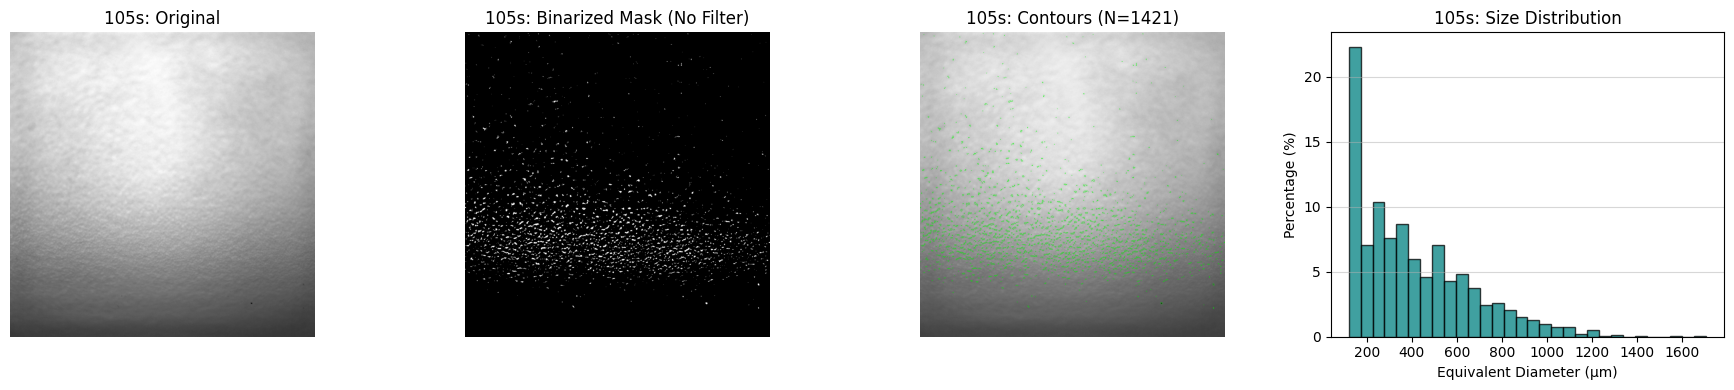

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
import pandas as pd

# --- 1. 処理設定 ---
folder_path = "/content/images"
image_paths = sorted(glob.glob(os.path.join(folder_path, "*.bmp")))[:105]

scale_factor = 150  # 1px = 100µm

time_list = []
mean_diameters = []
max_diameters = []
dist_data_105 = []

# 105枚目の可視化用データ保持
img_105_orig = None
mask_105 = None
contours_105 = None

print(f"全 {len(image_paths)} 枚の画像を処理中...")

# --- 2. 画像の連続読み込みと解析 ---
for idx, path in enumerate(image_paths):
    sec = idx + 1

    img_gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img_gray is None:
        continue

    # 微弱なぼかしのみ残し、適応的二値化を実行
    blurred = cv2.GaussianBlur(img_gray, (3, 3), 0)
    flocs_mask = cv2.adaptiveThreshold(blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 31, 5)

    # 【変更点】微小なフロックを消してしまうモルフォロジー処理(MORPH_OPEN)を無効化
    # kernel = np.ones((3, 3), np.uint8)
    # flocs_mask = cv2.morphologyEx(flocs_mask, cv2.MORPH_OPEN, kernel, iterations=1)

    contours, _ = cv2.findContours(flocs_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    diameters_um = []

    if sec == 105:
        img_105_orig = img_gray.copy()
        mask_105 = flocs_mask.copy()
        contours_105_list = []

    for cnt in contours:
        area = cv2.contourArea(cnt)
        # 【変更点】限界まで拾うため、面積0より大きいもの（実質1ピクセル以上）をすべて対象に
        if area > 0:
            diameter_px = 2 * np.sqrt(area / np.pi)
            diameter_um = diameter_px * scale_factor
            diameters_um.append(diameter_um)

            if sec == 105:
                contours_105_list.append(cnt)

    time_list.append(sec)
    if len(diameters_um) > 0:
        mean_diameters.append(np.mean(diameters_um))
        max_diameters.append(np.max(diameters_um))
    else:
        mean_diameters.append(np.nan)
        max_diameters.append(np.nan)

    if sec == 105:
        dist_data_105 = diameters_um
        contours_105 = contours_105_list

# --- 3. Excelファイルへの出力 ---
excel_filename = "/content/Floc_Analysis_Result_MinLimit.xlsx"
with pd.ExcelWriter(excel_filename) as writer:
    # シート1: 時間変化
    df_time = pd.DataFrame({"時間 (秒)": time_list, "平均径 (µm)": mean_diameters, "最大径 (µm)": max_diameters})
    df_time.to_excel(writer, sheet_name="時間変化", index=False)

    # シート2: 粒度分布（105秒のみ）
    if len(dist_data_105) > 0:
        counts, bin_edges = np.histogram(dist_data_105, bins=30)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        percentages = counts / len(dist_data_105) * 100
        df_dist = pd.DataFrame({
            "105秒_粒径(µm)": np.round(bin_centers, 1),
            "105秒_数": counts,
            "105秒_割合(%)": np.round(percentages, 2)
        })
    else:
        df_dist = pd.DataFrame({"105秒_粒径(µm)": [], "105秒_数": [], "105秒_割合(%)": []})

    df_dist.to_excel(writer, sheet_name="粒度分布_105秒", index=False)

# --- 4. グラフと画像描画 ---
plt.figure(figsize=(9, 4))
plt.plot(time_list, mean_diameters, marker='.', label="Mean Diameter (µm)", color='blue', linestyle='-')
plt.plot(time_list, max_diameters, marker='.', label="Max Diameter (µm)", color='red', linestyle='-')
plt.title("Time vs. Floc Diameter (1 to 105 sec)")
plt.xlabel("Time (sec)")
plt.ylabel("Diameter (µm)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(18, 4))

axes[0].imshow(img_105_orig, cmap='gray')
axes[0].set_title("105s: Original")
axes[0].axis('off')

axes[1].imshow(mask_105, cmap='gray')
axes[1].set_title("105s: Binarized Mask (No Filter)")
axes[1].axis('off')

img_contours = cv2.cvtColor(img_105_orig, cv2.COLOR_GRAY2BGR)
cv2.drawContours(img_contours, contours_105, -1, (0, 255, 0), 1)
axes[2].imshow(cv2.cvtColor(img_contours, cv2.COLOR_BGR2RGB))
axes[2].set_title(f"105s: Contours (N={len(dist_data_105)})")
axes[2].axis('off')

if len(dist_data_105) > 0:
    weights = np.ones(len(dist_data_105)) / len(dist_data_105) * 100
    axes[3].hist(dist_data_105, bins=30, weights=weights, color='teal', alpha=0.75, edgecolor='black')
    axes[3].set_title("105s: Size Distribution")
    axes[3].set_xlabel("Equivalent Diameter (µm)")
    axes[3].set_ylabel("Percentage (%)")
    axes[3].grid(axis='y', alpha=0.5)
else:
    axes[3].set_title("105s: No flocs found")
    axes[3].axis('off')

plt.tight_layout()
plt.show()